# Séance 3 — Nettoyage et qualité des données

**Durée pratique : 3 h 30** &nbsp;·&nbsp; Ateliers 3.1 à 3.4

## Ce que vous saurez faire à la fin

- classer les valeurs manquantes et choisir un traitement adapté à chaque colonne ;
- détecter les valeurs aberrantes par écart interquartile et par score z, et arbitrer ;
- normaliser des chaînes de caractères pour éliminer les faux doublons ;
- écrire une fonction de nettoyage idempotente qui journalise ce qu'elle modifie.

> **Le principe directeur de la séance.** Une décision de nettoyage n'est jamais neutre :
> elle change les résultats en aval. Chaque choix doit donc être **explicite, justifié et
> tracé**. Un pipeline qui supprime 4 % des lignes sans le dire est un pipeline dangereux.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [71]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


In [72]:
def parse_price(series):
    """Convertit une colonne de prix mixte (nombre ou texte '123,45 EUR') en float."""
    text = series.astype(str).str.replace(' EUR', '', regex=False)
    return pd.to_numeric(text.str.replace(',', '.', regex=False).str.strip(),
                         errors='coerce')


sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
customers = pd.read_csv(RAW_DIR / 'clients.csv')
sales['prix_unitaire'] = parse_price(sales['prix_unitaire'])

print(sales.shape, customers.shape)

(17609, 11) (3060, 5)


---
## Atelier 3.1 — Cartographier les valeurs manquantes (60 min)

### Partie guidée

Avant de choisir un traitement, il faut savoir **pourquoi** la valeur est absente.
La typologie classique distingue trois cas :

| Type | Signification | Conséquence |
|---|---|---|
| MCAR | absence totalement aléatoire | supprimer ne biaise pas, on perd seulement de la puissance |
| MAR | absence expliquée par d'autres colonnes | imputation conditionnelle possible et souhaitable |
| MNAR | absence liée à la valeur elle-même | tout traitement biaise ; l'absence doit devenir une information |

On ne peut pas prouver le type à partir des seules données. On l'argumente à partir de la
connaissance du processus qui les a produites.

In [73]:
missing_summary = pd.DataFrame({
    'nb_manquants': sales.isna().sum(),
    'taux_pct': (sales.isna().mean() * 100).round(2),
})
missing_summary[missing_summary['nb_manquants'] > 0].sort_values('taux_pct', ascending=False)

,nb_manquants,taux_pct
remise_pct,1941,11.02
date_commande,350,1.99


**Lecture.** Si les deux profils sont semblables, l'hypothèse MCAR est plausible et une
imputation simple par zéro se défend (pas de remise saisie = pas de remise accordée).
S'ils diffèrent nettement, l'absence porte de l'information : créer un indicateur
`remise_absente` devient préférable à une imputation silencieuse.

### Partie autonome

In [74]:
# Q1. Même analyse pour la colonne 'age' de customers : les âges manquants se
#     concentrent-ils sur certains segments ou certaines villes ?

age_missing_segment = (
    customers.groupby('segment')['age']
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
)

age_missing_ville = (
    customers.groupby('ville')['age']
    .apply(lambda x: x.isna().mean() * 100)
    .round(2)
)

print("Âges manquants par segment :")
print(age_missing_segment)

print("\nÂges manquants par ville :")
print(age_missing_ville)

Âges manquants par segment :
segment
Association      6.53
Particulier      5.71
Professionnel    6.32
Name: age, dtype: float64

Âges manquants par ville :
ville
  Bordeaux        9.09
  Lille           4.00
  Lyon            0.00
  Marseille       4.76
  Nantes          7.14
  Paris           4.17
  Strasbourg     16.00
  Toulouse        7.41
BORDEAUX         12.24
Bordeaux          6.82
LILLE             4.17
LYON              3.45
Lille             6.49
Lyon              5.71
MARSEILLE        10.53
Marseille         7.94
NANTES            9.62
Nantes            6.13
PARIS             9.52
Paris             3.66
STRASBOURG        0.00
Strasbourg        6.00
TOULOUSE          4.88
Toulouse          4.86
bordeaux          5.00
lille             6.25
lyon             13.95
marseille         4.00
nantes            4.35
paris             7.14
strasbourg        1.96
toulouse          2.33
Name: age, dtype: float64


In [75]:
# Q2. Rédiger une stratégie colonne par colonne, sous forme de dictionnaire.
#     Valeurs autorisées : 'drop_row', 'fill_zero', 'fill_median',
#     'fill_median_by_group', 'add_indicator', 'keep_as_is'.
#     La justification est OBLIGATOIRE : c'est elle qui sera évaluée, pas le choix lui-même.
missing_value_strategy = {
    'date_commande': (
        'drop_row',
        'une commande sans date est inexploitable pour toute analyse temporelle'
    ),
    'remise_pct': (
        'fill_zero',
        'une remise manquante peut être interprétée comme aucune remise appliquée'
    ),
    'age': (
        'fill_median_by_group',
        'la médiane du groupe limite l influence des valeurs aberrantes et conserve les différences entre segments'
    ),
    'cout_achat': (
        'fill_median',
        'le coût d achat est numérique et la médiane est robuste aux valeurs extrêmes'
    ),
}

for column, (action, rationale) in missing_value_strategy.items():
    print(f'{column:<16} {action:<24} {rationale}')

date_commande    drop_row                 une commande sans date est inexploitable pour toute analyse temporelle
remise_pct       fill_zero                une remise manquante peut être interprétée comme aucune remise appliquée
age              fill_median_by_group     la médiane du groupe limite l influence des valeurs aberrantes et conserve les différences entre segments
cout_achat       fill_median              le coût d achat est numérique et la médiane est robuste aux valeurs extrêmes


---
## Atelier 3.2 — Valeurs aberrantes : deux méthodes, deux verdicts (55 min)

### Partie guidée

In [76]:
def iqr_bounds(series, factor=1.5):
    """Bornes de Tukey : robustes, car fondées sur des quantiles."""
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    return q1 - factor * spread, q3 + factor * spread


def zscore_bounds(series, n_std=3):
    """Bornes par score z : sensibles, car moyenne et écart type sont eux-mêmes
    tirés vers le haut par les valeurs extrêmes."""
    mean, std = series.mean(), series.std()
    return mean - n_std * std, mean + n_std * std


quantity = sales['quantite']
for label, (lower, upper) in [('IQR    ', iqr_bounds(quantity)),
                              ('score z', zscore_bounds(quantity))]:
    n_flagged = ((quantity < lower) | (quantity > upper)).sum()
    print(f'{label} bornes [{lower:8.2f} ; {upper:8.2f}]  ->  {n_flagged:>4} valeurs signalées')

IQR     bornes [   -2.00 ;     6.00]  ->    74 valeurs signalées
score z bornes [ -119.00 ;   127.75]  ->    61 valeurs signalées


Les deux méthodes ne s'accordent pas, et l'écart est instructif. Le score z est calculé à
partir de la moyenne et de l'écart type, deux statistiques que les valeurs extrêmes
**déforment elles-mêmes**. Quelques quantités à 1 000 suffisent à gonfler l'écart type au
point que ces mêmes valeurs passent sous le seuil de détection. L'IQR, fondé sur des
quantiles, ne souffre pas de cet effet.

In [77]:
# Regarder les valeurs concernées avant de décider quoi que ce soit
print('Quantités les plus élevées :')
print(sales.nlargest(8, 'quantite')[['id_commande', 'quantite', 'prix_unitaire', 'statut']])
print()
print('Quantités négatives :', (sales['quantite'] < 0).sum())
print(sales[sales['quantite'] < 0][['id_commande', 'quantite', 'statut']].head())

Quantités les plus élevées :
      id_commande  quantite  prix_unitaire    statut
3498   CMD0000204      1199         542.83     livre
4204   CMD0000063      1163         949.23     livre
360    CMD0004120      1128         413.11     livre
10360  CMD0016201      1098         982.04  retourne
15880  CMD0003400      1092          66.77     livre
6745   CMD0002168      1081          90.34  retourne
12339  CMD0002491      1053         903.19  retourne
12341  CMD0006289      1002         614.04     livre

Quantités négatives : 30
     id_commande  quantite    statut
46    CMD0006153        -3     livre
757   CMD0017746        -4  retourne
1409  CMD0014959        -1     livre
1473  CMD0005010        -4    annule
1896  CMD0003955        -4     livre


**Deux problèmes de nature différente sont ici confondus.** Les quantités négatives sont
*impossibles* : c'est une erreur de saisie ou de signe, elle se corrige ou se supprime sans
état d'âme. Les quantités à 800 sont *improbables* mais pas impossibles : il peut s'agir de
commandes professionnelles légitimes. Les traiter de la même façon serait une faute
méthodologique.

### Partie autonome

In [78]:
# Q3. Écrire une fonction qui, pour une colonne donnée, renvoie un DataFrame comparant
#     les deux méthodes : nb détectés, part en %, valeur min et max des points signalés.

def compare_outlier_methods(df, column):
    s = df[column].dropna()

    # Méthode IQR
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    mask_iqr = (s < lower_bound) | (s > upper_bound)

    # Méthode Z-score
    mean = s.mean()
    std = s.std()

    if std == 0:
        mask_zscore = s.notna() & False
    else:
        z_scores = (s - mean) / std
        mask_zscore = z_scores.abs() > 3

    def summary(mask, method):
        values = s[mask]

        return {
            'methode': method,
            'nb_detectes': values.count(),
            'part_pct': round(values.count() / len(s) * 100, 2),
            'min': values.min(),
            'max': values.max()
        }
    return pd.DataFrame([
        summary(mask_iqr, 'IQR'),
        summary(mask_zscore, 'Z-score')
    ])

compare_outlier_methods(sales, 'quantite')
compare_outlier_methods(sales, 'prix_unitaire')

,methode,nb_detectes,part_pct,min,max
0,IQR,0,0.0,NaN,NaN
1,Z-score,0,0.0,NaN,NaN


<Figure size 800x500 with 0 Axes>

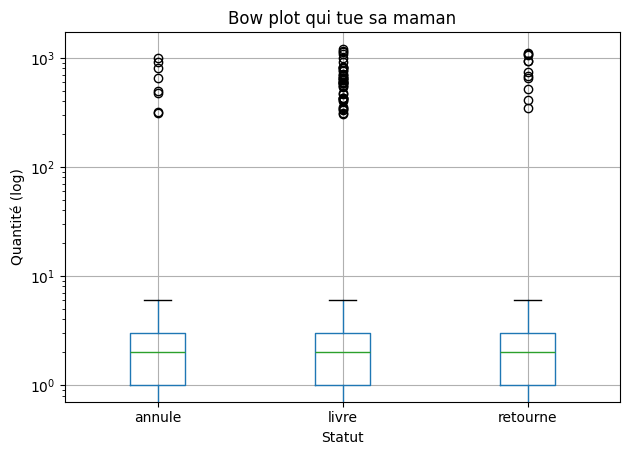

In [79]:
# Q4. Visualiser. Un boxplot par statut pour la quantité, en échelle logarithmique
#     sur l'axe des ordonnées (sans quoi les valeurs extrêmes écrasent tout le reste).

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sales.boxplot(
    column='quantite',
    by='statut',
    showfliers=True,     
)

plt.yscale('log')       
plt.title('Bow plot qui tue sa maman')
plt.suptitle('')         
plt.xlabel('Statut')
plt.ylabel('Quantité (log)')
plt.tight_layout()
plt.show()


In [80]:
# Q5. Appliquer un traitement différencié et JOURNALISER ce qui est fait :
#       - quantités négatives : à décider et justifier ;
#       - quantités au-delà de la borne haute IQR : à décider et justifier.
#     La fonction renvoie (df_traité, log) où log est un dict des comptes.

import matplotlib.pyplot as plt

def handle_quantity_outliers(df, iqr_factor=1.5):
    """Traite les quantités aberrantes en distinguant erreur (impossible)
    et cas rare légitime (improbable). Renvoie (df_traité, log)."""
    df_treated = df.copy()
    log = {}

    # --- 1. Quantités négatives : objectivement impossible
    # Justification : une quantité vendue ne peut pas être négative dans la
    # réalité métier.c'est sans doute une erreur de saisie (signe erroné), 
    # on corrige (valeur absolue) plutôt que de supprimer
    # toute la ligne, qui reste exploitable par ailleurs.
    is_negative = df_treated['quantite'] < 0
    log['quantites_negatives_corrigees'] = int(is_negative.sum())
    df_treated.loc[is_negative, 'quantite'] = df_treated.loc[is_negative, 'quantite'].abs()

    # --- 2. Quantités au-dessus de la borne haute IQR : improbable  
    # Justification : une grosse quantité positive peut correspondre à une
    # commande professionnelle ou un réassort de magasin -> ne pas supprimer (on
    # effacerait un segment de clientèle réel). On se contente de signaler la valeur abérante
    # pour un contrôle qualité manuel, sans modifier la valeur elle-même.
    q1, q3 = df_treated['quantite'].quantile([0.25, 0.75])
    upper_bound = q3 + iqr_factor * (q3 - q1)

    is_high = df_treated['quantite'] > upper_bound
    log['quantites_improbables_signalees'] = int(is_high.sum())
    log['borne_haute_iqr'] = round(upper_bound, 2)
    df_treated['quantite_a_verifier'] = is_high

    return df_treated, log


sales_fixed, quantity_log = handle_quantity_outliers(sales)
print(quantity_log)



{'quantites_negatives_corrigees': 30, 'quantites_improbables_signalees': 61, 'borne_haute_iqr': 6.0}


---
## Atelier 3.3 — Doublons et incohérences textuelles (45 min)

### Partie guidée

In [81]:
print('Doublons stricts (toutes colonnes identiques) :', sales.duplicated().sum())
print('Doublons sur id_commande seul                 :', sales.duplicated('id_commande').sum())

Doublons stricts (toutes colonnes identiques) : 240
Doublons sur id_commande seul                 : 240


Les deux comptes diffèrent : certaines lignes partagent un identifiant de commande sans
être identiques. Avant de supprimer, il faut regarder ce qui les distingue.

In [82]:
repeated_ids = sales[sales.duplicated('id_commande', keep=False)]['id_commande'].unique()[:2]
sales[sales['id_commande'].isin(repeated_ids)].sort_values('id_commande')

,id_commande,date_commande,id_client,id_produit,id_magasin,quantite,prix_unitaire,remise_pct,canal,statut,ville_livraison
13,CMD0000105,2023/07/29 19:47,C01517,P0014,M99,2,1053.99,NaN,web,livre,Lyon
13443,CMD0000105,2023/07/29 19:47,C01517,P0014,M99,2,1053.99,NaN,web,livre,Lyon
18,CMD0000173,24-05-2023,C02747,P0002,M02,2,538.60,15.0,BOUTIQUE,annule,Marseille
2557,CMD0000173,24-05-2023,C02747,P0002,M02,2,538.60,15.0,BOUTIQUE,annule,Marseille


In [83]:
# Faux doublons textuels : la même ville écrite de plusieurs façons
print(sales['ville_livraison'].value_counts().head(12))

ville_livraison
Toulouse      1560
Lyon          1523
Paris         1521
Bordeaux      1510
Lille         1475
Marseille     1473
Nantes        1471
Strasbourg    1379
STRASBOURG     295
lyon           278
LYON           275
paris          275
Name: count, dtype: int64


In [84]:
def normalize_text(series):
    """Casse, espaces et accents : trois sources de faux niveaux."""
    text = series.astype(str).str.strip().str.lower()
    text = text.str.normalize('NFKD').str.encode('ascii', 'ignore').str.decode('utf-8')
    return text.str.replace(r'\s+', ' ', regex=True)


print('Modalités avant normalisation :', sales['ville_livraison'].nunique())
print('Modalités après normalisation :', normalize_text(sales['ville_livraison']).nunique())

Modalités avant normalisation : 33


Modalités après normalisation : 9


### Le piège : ne jamais normaliser les colonnes identifiantes

La tentation est grande d'écrire `for column in df.select_dtypes('object'): df[column] = normalize_text(df[column])`
et d'en finir. **C'est une erreur qui casse silencieusement tout le pipeline.** Les colonnes
`id_client`, `id_produit`, `id_magasin` sont du texte pour pandas, mais ce sont des **clés**.
Les passer en minuscules transforme `P0027` en `p0027`, et la jointure de la séance 6 ne
trouvera plus aucune correspondance : vous obtiendrez un jeu entièrement vide, sans la
moindre erreur levée.

Déclarez donc explicitement les colonnes à normaliser, plutôt que de les déduire du type.

In [85]:
print(sales)

      id_commande     date_commande id_client id_produit id_magasin  quantite  prix_unitaire  remise_pct      canal    statut ville_livraison
0      CMD0003112  2024/01/18 19:53    C02300      P0009        M05         3         160.66         5.0  telephone  retourne           Lille
1      CMD0000107        08/01/2024    C02791      P0028        M03         2          70.48         NaN   boutique     livre        Toulouse
2      CMD0010050        2023-04-15    990031      P0017        M04         3         691.12         0.0   boutique     livre       MARSEILLE
3      CMD0001979       06 Nov 2024    C01883      P0010        M04         4         570.25         0.0        WEB  retourne       Marseille
4      CMD0010513        2024-11-02    C00571      P0024        M02         2        1058.05        10.0       web      livre       Marseille
...           ...               ...       ...        ...        ...       ...            ...         ...        ...       ...             ...
17604 

In [86]:
TEXT_COLUMNS = ['canal', 'statut', 'ville_livraison']
KEY_COLUMNS = ['id_commande', 'id_client', 'id_produit', 'id_magasin']

trial = sales.copy()

# Doublons avant normalisation
doublons_avant = trial.duplicated().sum()

# Normalisation uniquement des colonnes descriptives
for column in TEXT_COLUMNS:
    trial[column] = normalize_text(trial[column])

# Doublons après normalisation
doublons_apres = trial.duplicated().sum()

print('Doublons avant normalisation :', doublons_avant)
print('Doublons après normalisation :', doublons_apres)

# Vérification : les clés n'ont pas été modifiées
print('Clés intactes :', trial[KEY_COLUMNS].equals(sales[KEY_COLUMNS]))

# La normalisation peut augmenter le nombre de doublons stricts :
# des lignes auparavant différentes peuvent devenir identiques après
# suppression des espaces, uniformisation de la casse, etc.

Doublons avant normalisation : 240
Doublons après normalisation : 240
Clés intactes : True


### Partie autonome

In [87]:
# Q6. Normalisation des colonnes textuelles

trial = sales.copy()

for col in TEXT_COLUMNS:
    trial[col] = trial[col].str.strip().str.lower()

# Recompter les doublons stricts
nb_doublons = trial.duplicated().sum()

print("Nombre de doublons stricts après normalisation :", nb_doublons)

# Le nombre de doublons peut augmenter car des lignes qui étaient
# différentes avant normalisation peuvent devenir identiques après
# suppression des espaces et passage en minuscules.

Nombre de doublons stricts après normalisation : 240


In [88]:
# Q7. Identifier les doublons métier

BUSINESS_COLUMNS = ['ville', 'segment', 'date_inscription', 'age']

# Lignes partageant les mêmes informations métier
doublons_metier = customers[
    customers.duplicated(subset=BUSINESS_COLUMNS, keep=False)
].sort_values(BUSINESS_COLUMNS)

print(doublons_metier)

# Nombre de couples de doublons
nb_couples = (
    doublons_metier.groupby(BUSINESS_COLUMNS)
    .size()
    .apply(lambda n: n * (n - 1) // 2)
    .sum()
)

print("Nombre de couples de doublons métier :", nb_couples)

     id_client date_inscription        segment       ville   age
14      C00015       2019-11-29    Particulier       Lyon   39.0
3047    990047       2019-11-29    Particulier       Lyon   39.0
1001    C01002       2022-05-30    Particulier    Bordeaux  41.0
3059    990059       2022-05-30    Particulier    Bordeaux  41.0
1241    C01242       2024-01-13    Particulier    Bordeaux  44.0
...        ...              ...            ...         ...   ...
3005    990005       2019-10-14  Professionnel       paris  34.0
1359    C01360       2021-04-02    Particulier  strasbourg  48.0
3056    990056       2021-04-02    Particulier  strasbourg  48.0
322     C00323       2021-04-03    Particulier    toulouse  41.0
3037    990037       2021-04-03    Particulier    toulouse  41.0

[120 rows x 5 columns]
Nombre de couples de doublons métier : 55


---
## Atelier 3.4 — Un module de nettoyage idempotent (50 min)

**Idempotent** signifie que réappliquer la fonction à son propre résultat ne change plus rien.
C'est une propriété essentielle : un pipeline relancé deux fois par erreur ne doit pas
produire un jeu de données différent.

In [89]:
def clean_sales(df, drop_negative_quantities=True, max_quantity=None, verbose=True):
    """Nettoie le jeu de ventes et renvoie (df_propre, log).

    Étapes attendues, dans cet ordre :
      1. copier le DataFrame reçu (ne jamais modifier l'entrée) ;
      2. convertir prix_unitaire en numérique ;
      3. normaliser les colonnes texte DESCRIPTIVES (jamais les identifiants) ;
      4. supprimer les doublons stricts ;
      5. convertir date_commande en datetime et supprimer les lignes sans date ;
      6. appliquer la stratégie retenue pour remise_pct ;
      7. traiter les quantités selon les paramètres ;
      8. calculer la colonne montant.

    Le log recense, pour chaque étape, le nombre de lignes ou de valeurs touchées.
    """
    log = {'lignes_initiales': len(df)}
    df = df.copy()

    # 2. Prix
    df['prix_unitaire'] = parse_price(df['prix_unitaire'])

    # 3. Texte descriptif
    for col in TEXT_COLUMNS:
        df[col] = normalize_text(df[col])

    # 4. Doublons
    doublons = df.duplicated().sum()
    df = df.drop_duplicates()
    log['doublons_supprimes'] = doublons

    # 5. Dates
    df['date_commande'] = pd.to_datetime(
        df['date_commande'],
        format='mixed',
        dayfirst=True,
        errors='coerce'
    )

    dates_invalides = df['date_commande'].isna().sum()
    df = df.dropna(subset=['date_commande'])
    log['dates_invalides_supprimees'] = dates_invalides

    # 6. Remise
    remises_invalides = df['remise_pct'].isna().sum()
    df['remise_pct'] = df['remise_pct'].fillna(0)
    log['remises_remplacees'] = remises_invalides

    # 7. Quantités
    if drop_negative_quantities:
        quantites_negatives = (df['quantite'] < 0).sum()
        df = df[df['quantite'] >= 0].copy()
        log['quantites_negatives_supprimees'] = quantites_negatives

    if max_quantity is not None:
        quantites_trop_elevees = (df['quantite'] > max_quantity).sum()
        df = df[df['quantite'] <= max_quantity].copy()
        log['quantites_superieures_supprimees'] = quantites_trop_elevees

    # 8. Montant
    df['montant'] = (
        df['quantite']
        * df['prix_unitaire']
        * (1 - df['remise_pct'] / 100)
    )

    log['lignes_finales'] = len(df)

    if verbose:
        for key, value in log.items():
            print(f'  {key:<28} {value}')

    return df, log


clean_sales_df, cleaning_log = clean_sales(
    pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
)

  lignes_initiales             17609
  doublons_supprimes           240
  dates_invalides_supprimees   347
  remises_remplacees           1874
  quantites_negatives_supprimees 30
  lignes_finales               16992


In [90]:
# Q8. Vérifier l'idempotence : un second passage ne doit rien changer.

second_pass, _ = clean_sales(clean_sales_df, verbose=False)

assert len(second_pass) == len(clean_sales_df), "la fonction n'est pas idempotente"
assert second_pass.equals(clean_sales_df), 'le second passage modifie encore des valeurs'
print('OK — fonction idempotente')

OK — fonction idempotente


In [91]:
# Export du résultat et du journal, pour la séance 4.

import json

save_dataset(clean_sales_df, 'ventes_nettoyees')

with open(PROCESSED_DIR / 'journal_nettoyage.json', 'w', encoding='utf-8') as file:
    json.dump(cleaning_log, file, indent=2, ensure_ascii=False, default=str)

kept_ratio = len(clean_sales_df) / cleaning_log['lignes_initiales']
print('Lignes conservées :', len(clean_sales_df), f'({kept_ratio:.1%} du brut)')

écrit : ventes_nettoyees.parquet (16992, 12)
Lignes conservées : 16992 (96.5% du brut)


---
## Livrable de la séance

- `src/cleaning.py` contenant `clean_sales`, importable et testée ;
- `data/processed/ventes_nettoyees.parquet` ;
- `data/processed/journal_nettoyage.json` ;
- le tableau des stratégies (question 2) avec sa justification écrite, colonne par colonne.

**Ce tableau sera repris tel quel dans votre note méthodologique de projet et vous sera
demandé en soutenance.** Attendez-vous à la question : *pourquoi la médiane plutôt que la
moyenne sur cette colonne ?*